In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 4
NY = 4
NZ = 4
NT = 4
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.01431587231642711 + 0.009578697847212124im 0.002247136681428382 - 0.016114034388760523im 0.02108729437736807 + 0.018793817460484093im -0.010339307015451887 + 0.009627216654395535im; -0.017669184669471087 - 0.0069336330137924305im -0.006086851608636732 - 0.007410203357801494im 0.0040273628639631845 - 0.0006612745270237138im -0.0029221428935830283 + 0.009669286590664im; 0.0008079349691311409 + 0.012175931668292846im 0.014242907737576253 + 0.01589106170048228im 0.02297730036249051 - 0.026780566203456074im 0.014065992120610467 - 0.003538159402167279im;;; -0.010971647593847472 + 0.02430593330893817im -0.025544537637662554 - 0.012406895485651975im -0.009962648790949654 - 0.004284906128809176im -0.0022166442413824134 + 0.015745846236023424im; 0.009423006894788057 - 0.006346340913084061im 0.0016651712637728126 + 0.012580830601667786im -0.005919428797072544 - 0.010720427192351011im 0.014903579610655351 - 0.0032133779

In [3]:
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [-0.49361167519302457 - 0.7504497368941808im 0.10908931432790968 + 0.39142587010558433im -0.37770723458609196 + 0.8071163751541225im 0.44299211863148413 + 1.2490680888640877im; 1.0863916301492131 - 0.23269178346124902im 0.7490341089069366 + 0.4696502414163904im -0.4172017350826957 - 1.9392719822527003im -0.5193843533042397 - 0.19144867810998123im; 2.263631544986963 - 0.3033008906564299im 1.7559255237262432 + 0.48372641097880903im 0.345640890945462 - 0.17706364770655383im -1.1894131967508563 - 0.9488429907108159im; -1.084536298336706 + 0.2298624247901269im 0.6029339801656176 + 0.4246913572903778im 0.06310492624845379 - 0.1992616669925571im 0.7447457508263857 + 1.043232760271424im]
 [0.3174393622319651 + 0.24673604350003828im -0.18676796424761258 + 0.8498512241768695im 0.7382921197001662 + 1.537867679500682im 1.0435416716946087 - 0.22276413060243236im; -1.1428056356482938 + 0.12696268040468361im 1.2470297494295102 + 1.360105295037712im 0.06546822847296738 

In [4]:
layer=CPTC_Layer(hop,W)

CPTC_Layer(Spin_matrix[[-0.49361167519302457 - 0.7504497368941808im 0.10908931432790968 + 0.39142587010558433im -0.37770723458609196 + 0.8071163751541225im 0.44299211863148413 + 1.2490680888640877im; 1.0863916301492131 - 0.23269178346124902im 0.7490341089069366 + 0.4696502414163904im -0.4172017350826957 - 1.9392719822527003im -0.5193843533042397 - 0.19144867810998123im; 2.263631544986963 - 0.3033008906564299im 1.7559255237262432 + 0.48372641097880903im 0.345640890945462 - 0.17706364770655383im -1.1894131967508563 - 0.9488429907108159im; -1.084536298336706 + 0.2298624247901269im 0.6029339801656176 + 0.4246913572903778im 0.06310492624845379 - 0.1992616669925571im 0.7447457508263857 + 1.043232760271424im], [0.3174393622319651 + 0.24673604350003828im -0.18676796424761258 + 0.8498512241768695im 0.7382921197001662 + 1.537867679500682im 1.0435416716946087 - 0.22276413060243236im; -1.1428056356482938 + 0.12696268040468361im 1.2470297494295102 + 1.360105295037712im 0.06546822847296738 + 1.08289

In [5]:
opt=Adam()

Adam(0.001, 0.9, 0.999, 1.0e-8, ComplexF64[0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im], ComplexF64[0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im; 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im 0.0 + 0.0im], 0)

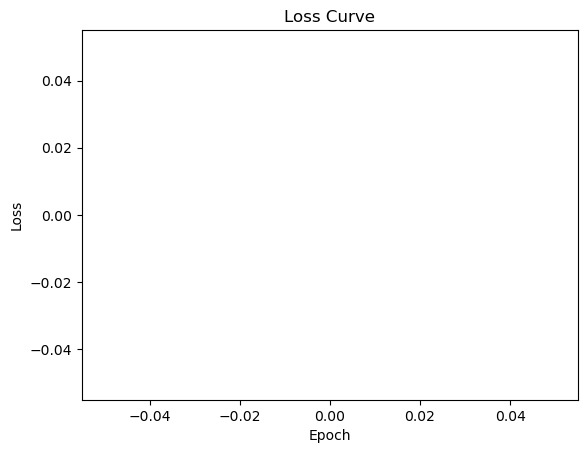

-0.013065039934008989 + 0.008513164276652635im
0.007658540890440631 + 0.016301354272100027im
-0.002239891789325525 - 0.0025975981751464993im
0.0031152642871147963 + 0.009240673158077386im
0.014776504672957916 - 0.0069655777444428794im
-0.0026247694572771197 - 0.009658506819726742im
0.02293495860311191 + 0.015106573911064465im
-0.001876300008400656 + 0.015473698250967668im
0.004390011291624675 - 0.0012144091655424297im-0.006922382770680106 + 0.025639910114424357im-0.00030030946562554877 - 0.0011871043228553358im0.018126946993243263 - 0.0021011214826334307im
-0.013065039934008989 + 0.008513164276652635im0.004149304752322083 + 0.007867868217439638im-0.015331791408101859 - 0.02253464753752575im0.012761431470416761 - 0.012032800894796901im
0.007658540890440631 + 0.016301354272100027im0.010420332028870074 - 0.010998010979020399im-0.025151976502997237 - 0.008746590345278707im-0.00444824182396024 + 0.01014512965282729im
-0.002239891789325525 - 0.0025975981751464993im0.023861812012042634 + 0.00

Excessive output truncated after 524297 bytes.

im -0.005930092128422202 + 0.013339578295780993im; 0.010460260009796418 + 0.008925996296888837im -0.011833077301038676 + 0.013770170639113097im -0.018358744547862862 - 

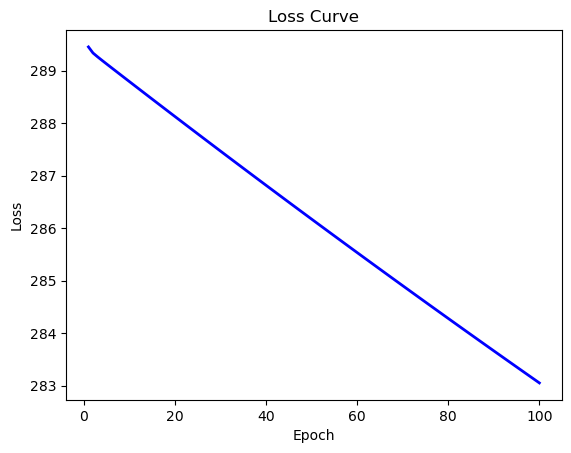

: 

In [ ]:
train(opt,[layer],x,t)